# Практика

### Cлучайный вопрос из [базы вопросов ЧГК](https://db.chgk.info/)

In [20]:
from bs4 import BeautifulSoup 
import requests

In [22]:
url = 'https://db.chgk.info/tour/mkm18_u'

try:
    page = requests.get(url, timeout=5) 
    page.encoding = 'utf-8'
    html = page.text
except requests.exceptions.RequestException as e:
    # сайт db.chgk.info бывает недоступен - тогда берем сохраненную копию страницы
    print('Сайт не ответил:', type(e).__name__, '- читаем сохраненную страницу chgk_mkm18_u.html')
    with open('chgk_mkm18_u.html', encoding='utf-8') as f:
        html = f.read()

soup = BeautifulSoup(html)

print(soup.prettify()[:2000]) # вся страница очень длинная, печатаем начало

Сайт не ответил: ConnectTimeout - читаем сохраненную страницу chgk_mkm18_u.html
<!DOCTYPE html PUBLIC "-//W3C//DTD XHTML 1.0 Strict//EN" "http://www.w3.org/TR/xhtml1/DTD/xhtml1-strict.dtd">
<html dir="ltr" lang="ru" xml:lang="ru" xmlns="http://www.w3.org/1999/xhtml">
 <head>
  <meta content="text/html; charset=utf-8" http-equiv="Content-Type"/>
  <title>
   Молодежный кубок мира. Сезон 2018–2019 | Что? Где? Когда?.
  </title>
  <meta content="zp6-H2" name="ver"/>
  <meta content="edge" http-equiv="X-UA-Compatible"/>
  <script type="text/javascript">
   window.google_analytics_uacct = "UA-17788280-2";
  </script>
  <link href="/favicon.ico" rel="shortcut icon" type="image/x-icon"/>
  <meta content="Что? Где? Когда?, ЧГК, Игра, Вопросы" name="keywords"/>
  <!--[if lte IE 6]>
<link type="text/css" rel="stylesheet" media="all" href="/sites/all/themes/zeropoint/css/ie6.css" />
<![endif]-->
  <!--[if IE 7]>
<link type="text/css" rel="stylesheet" media="all" href="/sites/all/themes/zeropoint/

In [23]:
questions = soup.find_all("div", {"class": "question"})
num_questions = len(questions)
num_questions

168

In [24]:
questions[0]

<div class="question" id="mkm18_u.1-1">
<p>
<strong class="Question">
<a href="/question/mkm18_u.1/1">
                   Вопрос 1
                  </a>
                  :
                 </strong>
<br/>
                 Шуточное мобильное приложение под названием «38» [тридцать восемь] анализирует фотографию животного и рассчитывает его параметры. В каких внесистемных единицах выдаются результаты измерений?
                </p>
<div class="collapsible collapsed">
<div class="collapse-processed">
<a href="#">
                   ...
                  </a>
</div>
<p>
<strong class="Answer">
                   Ответ:
                  </strong>
                  в попугаях.
                 </p>
<p>
<strong class="Comments">
                   Комментарий:
                  </strong>
                  38 попугаев, как известно, – длина удава.
                 </p>
<p>
<strong class="Sources">
                   Источник(и):
                  </strong>
                  http://www.maxim

In [25]:
questions[9].find_all('p')

[<p>
 <strong class="Question">
 <a href="/question/mkm18_u.1/10">
                    Вопрос 10
                   </a>
                   :
                  </strong>
                  В некоторых американских библиотеках есть особая стойка, где можно взять ИХ. Берут обычно весной, а возвращают осенью. Согласно пословице, всякое ОНО знает своё время. Назовите ЕГО.
                 </p>,
 <p>
 <strong class="Answer">
                    Ответ:
                   </strong>
                   семя.
                  </p>,
 <p>
 <strong class="PassCriteria">
                    Зачёт:
                   </strong>
                   семечко; семена; зерно; зёрнышко.
                  </p>,
 <p>
 <strong class="Comments">
                    Комментарий:
                   </strong>
                   любой желающий может взять семена, вырастить урожай и вернуть осенью семена в библиотеку.
                  </p>,
 <p>
 <strong class="Sources">
                    Источник(и):
            

## Как выбрать случайный вопрос из списка questions?

In [26]:
# решение

from random import randint

num = randint(0, num_questions - 1) # randint включает правую границу, а последний индекс - num_questions - 1

In [ ]:
q = questions[num].find_all('p')[0]
print(q.text)




                   Вопрос 162
                  
                  :
                 
                 Жители Гренландии традиционно украшают ИХ миниатюрными рукавицами или унтами из тюленьей кожи. Правда, в Гренландию ИХ приходится завозить, так как собственных нет из-за слишком холодного климата. Назовите ИХ.
                


In [ ]:
def get_text_q(q):
    return q.text.split(':')[-1].split('\n                 ')[-1].split('\n')[0]

def get_text_a(a):
    return a.text.split('\n                  ')[-1].split('.')[0]

for quention in questions[:5]:
    q = quention.find_all('p')[0]
    print(get_text_q(q))

Шуточное мобильное приложение под названием «38» [тридцать восемь] анализирует фотографию животного и рассчитывает его параметры. В каких внесистемных единицах выдаются результаты измерений?
На языке ацтеков слово «айотль» означает черепаху, а слово «точтли» – кролика. Переведите с ацтекского на русский слово «айоточтли».
Героиня античного мифа Пирена полюбила Геракла и скрывалась от родителей в скалистой местности. Точное место неизвестно, но, скорее всего, находится на территории одной из трёх современных стран. Назовите любую из них.
В статье Википедии сказано, что некий англичанин заработал ударным трудом 300 миллионов долларов и признан самым богатым среди своих коллег. Назовите эту звезду.
Карикатурист Анна Новикова изобразила ЕГО в виде хищной картошки рядом с белорусским флагом. Оригинальный ОН тоже обладает чертами животного и растения одновременно. Назовите ЕГО.


'ёлки'

In [65]:
# Добавим задержку между вопросом и ответом

from random import randint
import time

num = randint(0, num_questions - 1)
# get_text_q(questions[num].find_all('p')[0])
q = get_text_q(questions[num].find_all('p')[0])
# questions[num].find_all('p')[1]
a = get_text_a(questions[num].find_all('p')[1])

# attributes = []
# attributes.append(questions[num].find_all('p')[2].text)
# attributes.append(questions[num].find_all('p')[3].text)
# try:
#     attributes.append(questions[num].find_all('p')[4].text)
# except:
#     pass
# try:
#     attributes.append(questions[num].find_all('p')[5].text)
# except:
#     pass
print(q)

# #time.sleep(60) # минута на размышление
time.sleep(10)

print(a)
# # print(attributes)

# for attr in attributes:
#     if attr.strip().startswith('Источник'):
#         print(attr)
#     if attr.strip().startswith('Автор'):
#         print(attr)

Популярность этих традиционных предметов в Японии возросла после аварии на станции «Фукусима», когда многие компании стали экономить электроэнергию. Назовите эти предметы одним словом.
веера


In [61]:
a

'ветер'

## Парсим данные из Wikipedia

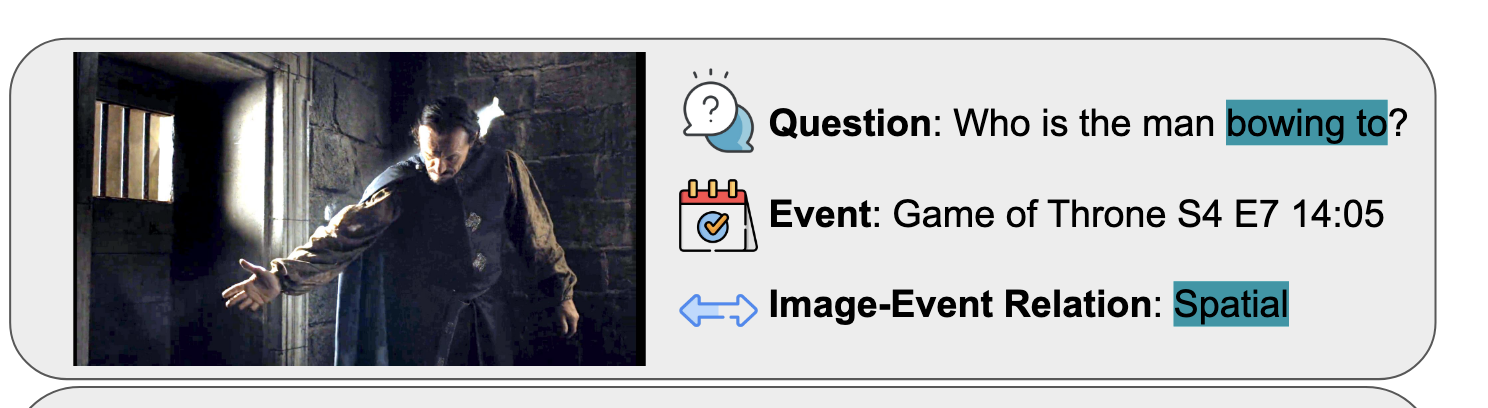

In [68]:
# Википедия не пускает запросы без понятного User-Agent (ответ 403), поэтому представимся
headers = {'User-Agent': 'DPOCourseBot/1.0 (educational example)'} # в заголовках только латиница

page = requests.get('https://ru.wikipedia.org/wiki/%D0%98%D1%81%D0%BA%D1%83%D1%81%D1%81%D1%82%D0%B2%D0%BE_%D0%BF%D1%80%D0%BE%D0%B3%D1%80%D0%B0%D0%BC%D0%BC%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D1%8F',
                    headers=headers, timeout=10)
page

<Response [200]>

In [69]:
soup = BeautifulSoup(page.text)
print(soup.prettify())

<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-enabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available skin-thumbsize-clientpref-standard skin-underline-clientpref-browser" dir="ltr" lang="ru">
 <head>
  <meta charset="utf-8"/>
  <title>
   Искусство программирования — Википедия
  </title>
  <script>
   (function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-enabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pin

In [76]:
p = soup.find_all('p')

In [77]:
len(p)

20

In [72]:
p[0:6]

[<p id="mwAw"><b id="mwBA">«Искусство программирования»</b> (<span about="#mwt2" data-mw='{"parts":[{"template":{"target":{"wt":"lang-en","href":"./Шаблон:Lang-en"},"params":{"1":{"wt":"The Art of Computer Programming"}},"i":0}}]}' id="mwBQ" typeof="mw:Nowiki mw:Transclusion"></span><a about="#mwt2" href="https://ru.wikipedia.org/wiki/Английский_язык" rel="mw:WikiLink" title="Английский язык">англ.</a><span about="#mwt2" typeof="mw:Entity"> </span><span about="#mwt2" id="mwBg" lang="en" style="font-style:italic;">The Art of Computer Programming</span><sup about="#mwt4" class="mw-ref reference" data-mw='{"name":"ref","attrs":{},"body":{"id":"mw-reference-text-cite_note-1"}}' id="cite_ref-1" rel="dc:references" typeof="mw:Extension/ref"><a href="#cite_note-1" id="mwBw"><span class="mw-reflink-text" id="mwCA"><span class="cite-bracket" id="mwCQ">[</span>1<span class="cite-bracket" id="mwCg">]</span></span></a></sup>) — фундаментальная <a href="https://ru.wikipedia.org/wiki/Монография" id=

In [73]:
p_clean = [par.text for par in p[0:6]]

In [74]:
p_clean

['«Искусство программирования» (англ.\xa0The Art of Computer Programming[1])\xa0— фундаментальная монография известного американского математика и специалиста в области компьютерных наук Дональда Кнута, посвящённая рассмотрению и анализу важнейших алгоритмов, используемых в информатике. В 1999\xa0году книга была признана одной из двенадцати лучших физико-математических монографий столетия[2].',
 'Проект написания книги был начат автором в 1962\xa0году. Изначально планировалось выпустить её одним томом, но объём материала оказался столь большим, что количество томов было увеличено до семи. Первые три тома были изданы достаточно быстро: том\xa01\xa0— в 1968\xa0году, том\xa02\xa0— в 1969\xa0году, том\xa03\xa0— в 1973\xa0году. После этого последовал перерыв до февраля 2005\xa0года, в котором автор опубликовал первую часть четвёртого тома. Было принято решение выпускать остальные части четвёртого тома приблизительно по две в год отдельными выпусками, после чего официально издать весь четвёр

In [75]:
with open('wikipedia.txt', 'w', encoding='utf-8') as infile:
    infile.write('\n'.join(p_clean)) # каждый абзац с новой строки